# Lab 2 — Part A: Data and baseline

## Data preparation

The shared module `lab2_utils.py` prepares the data identically for all parts of the lab:

- **Loading:** the CSV is read with `keep_default_na=False`, so `NA` stays a category ("feature does not exist", e.g. no pool) instead of a missing value.
- **Corrections from Lab 1:** the typo `Garage Yr Blt` = 2207 is set to 2007; missing basement values belong to houses without a basement and are set to 0.
- **Target:** `SalePrice` is cut into the 6 classes of the assignment (<100k, 100–130k, 130–180k, 180–250k, 250–400k, ≥400k), labelled 0–5. `SalePrice` itself is removed from the features.
- **Encoding:** `Order` and `PID` are identifiers and are dropped. All categorical features, including `MS SubClass` (numbers that stand for categories), are one-hot encoded, giving 333 features. Remaining missing numerical values (e.g. `Lot Frontage`) are left as NaN, since XGBoost handles them natively. Other encodings are compared in Part B.
- **Split:** a fixed stratified 80/20 train-test split (`random_state=42`) is used by everyone; the test set is only used at the end.

The classes are imbalanced: the largest class (130–180k) has 1,037 houses, the smallest (≥400k) only 64.

In [ ]:
import xgboost, optuna, plotly
print(xgboost.__version__, optuna.__version__, plotly.__version__)

In [8]:
from lab2_utils import get_data, get_split, CLASS_NAMES

X, y = get_data()
print("X:", X.shape)
print("Text columns left:", X.select_dtypes(exclude="number").shape[1])
print(y.value_counts().sort_index())

X: (2930, 333)
Text columns left: 0
PriceClass
0     237
1     509
2    1037
3     686
4     397
5      64
Name: count, dtype: int64


## Baseline: XGBoost with default settings

In [9]:
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, accuracy_score

X_train, X_test, y_train, y_test = get_split(X, y)

baseline = XGBClassifier(random_state=42)
baseline.fit(X_train, y_train)

for name, X_, y_ in [("train", X_train, y_train), ("test", X_test, y_test)]:
    pred = baseline.predict(X_)
    print(f"{name}: macro-F1 = {f1_score(y_, pred, average='macro'):.3f}, "
          f"accuracy = {accuracy_score(y_, pred):.3f}")

print("F1 per class (test):", f1_score(y_test, baseline.predict(X_test), average=None).round(2))

train: macro-F1 = 1.000, accuracy = 1.000
test: macro-F1 = 0.748, accuracy = 0.782
F1 per class (test): [0.71 0.68 0.82 0.8  0.84 0.64]


**Interpretation — Baseline**

- **Overfitting:** the model classifies every training house correctly (macro-F1 = 1.000), but reaches only 0.748 on unseen houses. It has largely memorized the training data instead of learning general rules (high variance). Hyperparameters that limit tree complexity (Part C) should reduce this gap.
- **Accuracy (0.782) is higher than macro-F1 (0.748)** because accuracy is dominated by the large classes, while macro-F1 gives every class the same weight.
- **Weakest class: ≥400k (F1 = 0.64).** Only 51 expensive houses are in the training set and 13 in the test set; 6 of these 13 were predicted as 250–400k. With so few examples, the model cannot learn this class well, and each single error changes its F1 strongly.
- **Errors happen between neighboring classes:** 122 of the 128 misclassified test houses were put into an adjacent price class. The classes are cuts of a continuous price, so houses close to a boundary (e.g. $128,000 vs. $132,000) are hard to separate. The narrow 100–130k class (F1 = 0.68) suffers most from this.

## Train-test split: 10% vs. 20%, with and without stratification

Each setup is repeated with 10 different random splits, to see how much the result depends on the split.

In [10]:
from sklearn.model_selection import train_test_split
import pandas as pd

rows = []
for test_size in [0.1, 0.2]:
    for stratify in [True, False]:
        for seed in range(10):
            Xtr, Xte, ytr, yte = train_test_split(
                X, y, test_size=test_size, random_state=seed,
                stratify=y if stratify else None)
            model = XGBClassifier(random_state=42).fit(Xtr, ytr)
            rows.append({
                "test_size": test_size,
                "stratified": stratify,
                "seed": seed,
                "macro_f1": f1_score(yte, model.predict(Xte), average="macro"),
                "houses_400k_in_test": (yte == 5).sum(),
            })

split_results = pd.DataFrame(rows)
summary = split_results.groupby(["test_size", "stratified"]).agg(
    mean_f1=("macro_f1", "mean"),
    std_f1=("macro_f1", "std"),
    min_400k_in_test=("houses_400k_in_test", "min"),
    max_400k_in_test=("houses_400k_in_test", "max"),
).round(3)
display(summary)

mean_f1  std_f1  min_400k_in_test  max_400k_in_test
test_size stratified                                                     
0.1       False         0.742   0.039                 3                11
          True          0.756   0.034                 6                 6
0.2       False         0.735   0.028                 8                18
          True          0.746   0.021                13                13

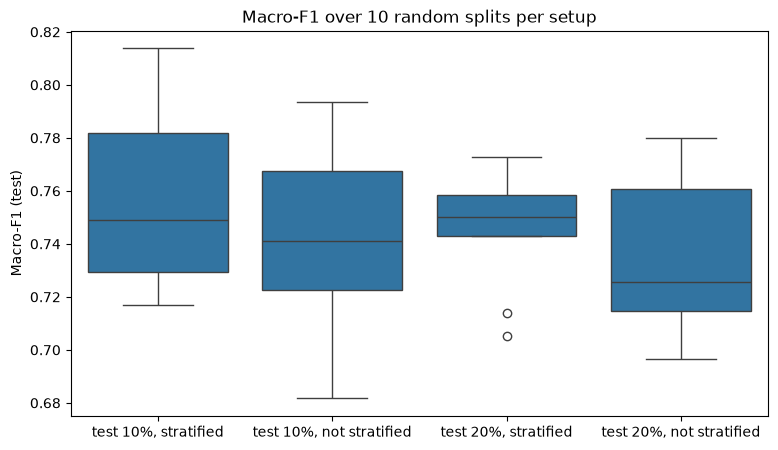

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

split_results["setup"] = (
    "test " + (split_results["test_size"] * 100).astype(int).astype(str) + "%, "
    + split_results["stratified"].map({True: "stratified", False: "not stratified"})
)

plt.figure(figsize=(9, 5))
sns.boxplot(data=split_results, x="setup", y="macro_f1")
plt.title("Macro-F1 over 10 random splits per setup")
plt.ylabel("Macro-F1 (test)")
plt.xlabel("")
plt.show()

**Interpretation — Train-test splits**

- **Stratification helps:** with stratification, every test set contains exactly the same number of the rarest class (6 houses ≥400k at 10%, 13 at 20%). Without it, this number varies between 3 and 11 (10%) or 8 and 18 (20%), so both training and test data change from split to split. As a result, stratified splits have a slightly higher mean macro-F1 and a lower standard deviation in both cases.
- **10% vs. 20%:** a 10% test set contains only ~290 houses and 6 of the rarest class, so a single error changes the score strongly: the standard deviation is higher (0.034–0.039 vs. 0.021–0.028). The mean is slightly higher at 10%, because the model is trained on more data (90%), but the difference is smaller than the spread between splits.
- **Bias-variance tradeoff:** a larger training set lets the model learn better (lower bias), while a larger test set makes the evaluation more reliable (lower variance of the score). A stratified 20% split is the most stable choice for a single split (std = 0.021), but even there two splits score clearly lower (~0.71), so one split alone is not enough to compare models. This motivates k-fold cross-validation.

## k-fold cross-validation: k=5 vs. k=10

Cross-validation is done on the training set only (80%), so the test set stays untouched.

In [12]:
import time
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score

cv_rows = []
for k in [5, 10]:
    for name, cv in [("stratified", StratifiedKFold(n_splits=k, shuffle=True, random_state=42)),
                     ("not stratified", KFold(n_splits=k, shuffle=True, random_state=42))]:
        start = time.time()
        scores = cross_val_score(XGBClassifier(random_state=42), X_train, y_train,
                                 cv=cv, scoring="f1_macro")
        cv_rows.append({"k": k, "cv": name,
                        "mean_f1": scores.mean(), "std_f1": scores.std(),
                        "time_s": time.time() - start})

cv_results = pd.DataFrame(cv_rows).round(3)
display(cv_results)

,k,cv,mean_f1,std_f1,time_s
0,5,stratified,0.722,0.020,11.969
1,5,not stratified,0.713,0.028,10.695
2,10,stratified,0.749,0.039,22.507
3,10,not stratified,0.698,0.046,22.514


**Interpretation — k-fold cross-validation**

- **Stratification matters even more here:** without it, k=10 drops to 0.698 with the highest spread (0.046). Each validation fold then contains only ~234 houses, and the number of houses ≥400k in a fold (on average ~5) can be much lower by chance, so the F1 of this class collapses in some folds. Stratification guarantees every fold the same class proportions.
- **k=10 vs. k=5 (stratified):** with k=10, each model is trained on 90% of the training data instead of 80%, so it learns slightly better and the estimate is less pessimistic (0.749 vs. 0.722, lower bias). But each validation fold is half as large, so the fold scores vary more (std 0.039 vs. 0.020, higher variance), and it takes about twice as long.
- **The single test split was slightly "lucky":** its macro-F1 (0.748) is higher than the 5-fold CV estimate (0.722), which matches the spread between splits seen above.

## Learning curve (bias-variance diagnosis)

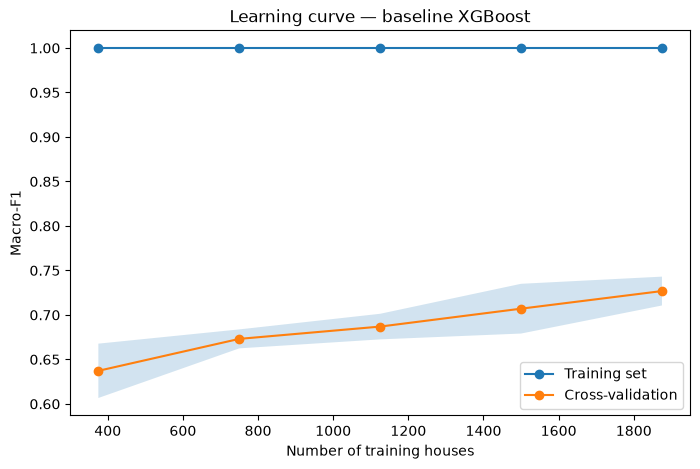

In [13]:
from sklearn.model_selection import learning_curve

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sizes, train_scores, cv_scores = learning_curve(
    XGBClassifier(random_state=42), X_train, y_train, cv=cv5, scoring="f1_macro",
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], shuffle=True, random_state=42)

plt.figure(figsize=(8, 5))
plt.plot(sizes, train_scores.mean(axis=1), "o-", label="Training set")
plt.plot(sizes, cv_scores.mean(axis=1), "o-", label="Cross-validation")
plt.fill_between(sizes, cv_scores.mean(axis=1) - cv_scores.std(axis=1),
                 cv_scores.mean(axis=1) + cv_scores.std(axis=1), alpha=0.2)
plt.xlabel("Number of training houses")
plt.ylabel("Macro-F1")
plt.title("Learning curve — baseline XGBoost")
plt.legend()
plt.show()

**Interpretation — Learning curve**

- The training score stays at 1.000 for every training size: the model always memorizes its training data.
- The cross-validation score rises steadily from 0.64 (375 houses) to 0.73 (1,875 houses) and has not flattened yet, so more data would still help.
- The large, persistent gap between the two curves shows **high variance (overfitting)**, not high bias. Limiting model complexity (e.g. `max_depth`, `min_child_weight`, regularization, Part C) is therefore more promising than a more complex model.

In [14]:
from sklearn.model_selection import RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scores = cross_val_score(XGBClassifier(random_state=42), X_train, y_train,
                         cv=rcv, scoring="f1_macro")
print("Mean of 15 folds:", round(scores.mean(), 3), "±", round(scores.std(), 3))
print("Mean per repetition:", scores.reshape(3, 5).mean(axis=1).round(3))

Mean of 15 folds: 0.726 ± 0.021
Mean per repetition: [0.722 0.73  0.724]


**Interpretation — Noise of the CV estimate**

Repeating the same stratified 5-fold CV with a different shuffle changes the mean macro-F1 between 0.722 and 0.730, only because the houses fall into different folds. Differences of about 0.01 between two experiments can therefore be noise: a change in data preparation or hyperparameters should improve the CV score clearly more than that to count as a real improvement.

## Conclusion — Part A

- Baseline XGBoost (default settings): macro-F1 = **0.748** on the test set, **0.722 ± 0.020** with stratified 5-fold CV. The model overfits strongly (macro-F1 = 1.000 on the training set).
- **Stratification** should always be used: the rarest class (≥400k) has only 64 houses, and without stratification its share varies strongly between splits and folds.
- For all further experiments we use **stratified 5-fold cross-validation on the training set**: it is stable (lowest spread) and twice as fast as k=10, which matters for hyperparameter optimization with many trials. The test set is only used at the end.
- The **learning curve** shows strong overfitting (training macro-F1 = 1.000, cross-validation 0.73) and a cross-validation score that still rises with more data: limiting model complexity during tuning is more promising than a more complex model.
- Repeating the same 5-fold CV with a different shuffle moves the score between 0.722 and 0.730, so **differences below ~0.01 between experiments can be noise**.